In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

In [2]:
df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    # nrows = 5000,
    low_memory=False
)

In [3]:
print(df.head())

         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  


In [4]:
print(df.shape)

(2075259, 9)


In [5]:
# null values
print(df.isnull().sum())

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 142.5 MB


In [7]:
# total null values
print("total null values:",df.isnull().sum().sum())

total null values: 181853


In [8]:
#rows with atleast one null value 
print(df.isnull().any(axis=1).sum())

25979


In [9]:
# duplicate values
df.duplicated().sum()

np.int64(0)

In [10]:
# data types
df.dtypes

Date                         str
Time                         str
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

In [11]:
df.nunique()

Date                     1442
Time                     1440
Global_active_power      4186
Global_reactive_power     532
Voltage                  2837
Global_intensity          221
Sub_metering_1             88
Sub_metering_2             81
Sub_metering_3             32
dtype: int64

In [12]:
df.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


In [13]:
# missing percent
(df.isnull().sum()/len(df))*100

Date                     0.000000
Time                     0.000000
Global_active_power      1.251844
Global_reactive_power    1.251844
Voltage                  1.251844
Global_intensity         1.251844
Sub_metering_1           1.251844
Sub_metering_2           1.251844
Sub_metering_3           1.251844
dtype: float64

In [14]:
df.nunique()[df.nunique() == 1]

Series([], dtype: int64)

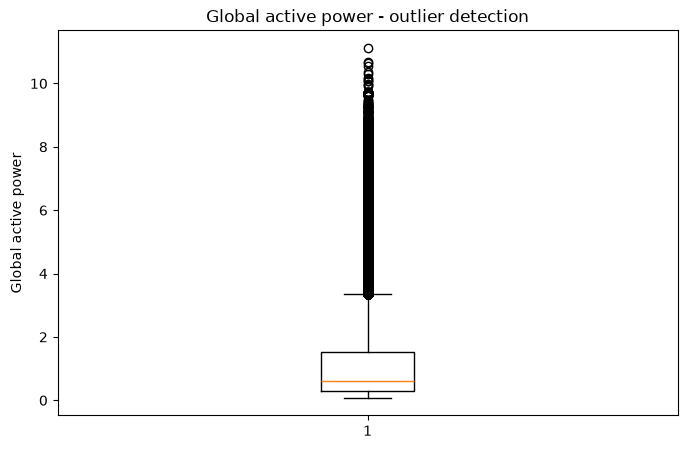

In [15]:
plt.figure(figsize = (8,5))
plt.boxplot(df['Global_active_power'].dropna())
plt.title("Global active power - outlier detection")
plt.ylabel("Global active power")
plt.show()

(array([1.201417e+06, 6.037440e+05, 1.514830e+05, 6.375200e+04,
        1.955700e+04, 7.078000e+03, 1.678000e+03, 4.890000e+02,
        7.200000e+01, 1.000000e+01]),
 array([ 0.076 ,  1.1806,  2.2852,  3.3898,  4.4944,  5.599 ,  6.7036,
         7.8082,  8.9128, 10.0174, 11.122 ]),
 <BarContainer object of 10 artists>)

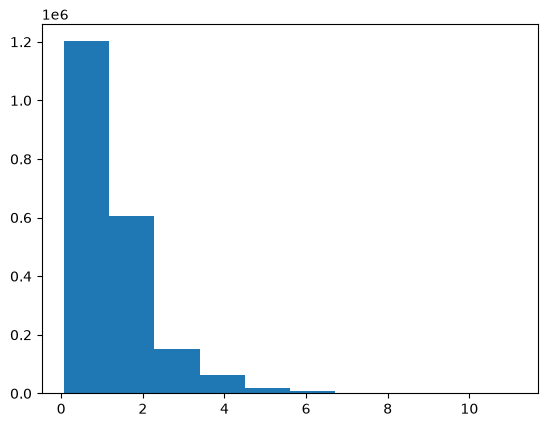

In [16]:
plt.hist(df['Global_active_power'])

In [17]:
# outliers
Q1 = df['Global_active_power'].quantile(0.25)
Q3 = df['Global_active_power'].quantile(0.75)

In [18]:
Q1

np.float64(0.308)

In [19]:
Q3

np.float64(1.528)

In [20]:
IQR = Q3 - Q1
lower = Q1-(1.5*IQR)
upper = Q3+(1.5 *IQR)

In [21]:
print("lower limit is:",lower)
print("upper limit is:",upper)

lower limit is: -1.522
upper limit is: 3.358


In [22]:
outliers = df[(df['Global_active_power']<lower) | (df['Global_active_power']>upper)]

In [23]:
print("no.of outliers:",len(outliers))

no.of outliers: 94907


In [24]:
outliers[['Date','Time','Global_active_power']].head(10)

,Date,Time,Global_active_power
0,16/12/2006,17:24:00,4.216
1,16/12/2006,17:25:00,5.360
2,16/12/2006,17:26:00,5.374
3,16/12/2006,17:27:00,5.388
4,16/12/2006,17:28:00,3.666
5,16/12/2006,17:29:00,3.520
6,16/12/2006,17:30:00,3.702
7,16/12/2006,17:31:00,3.700
8,16/12/2006,17:32:00,3.668
9,16/12/2006,17:33:00,3.662


In [25]:
outliers['Global_active_power'].describe() # it shows that the outliers are above the upper limit(3.358),because min is 3.360

count    94907.000000
mean         4.302087
std          0.899524
min          3.360000
25%          3.650000
50%          3.994000
75%          4.698000
max         11.122000
Name: Global_active_power, dtype: float64

In [26]:
# checking highest consumption reading
outliers.sort_values(
    by = 'Global_active_power',
    ascending=False)[['Date','Time','Global_active_power']].head(10)    

,Date,Time,Global_active_power
1150545,22/2/2009,17:09:00,11.122
112450,4/3/2007,19:34:00,10.670
112449,4/3/2007,19:33:00,10.650
1150544,22/2/2009,17:08:00,10.536
1029775,30/11/2008,20:19:00,10.348
968160,19/10/2008,01:24:00,10.290
586200,27/1/2008,19:24:00,10.162
112448,4/3/2007,19:32:00,10.154
1029773,30/11/2008,20:17:00,10.074
968161,19/10/2008,01:25:00,10.064


In [27]:
outlier_percent = (len(outliers)/len(df))*100
print(outlier_percent)

4.5732604942322865


In [28]:
# conversion of date and time col from text to datetime 
df['Datetime'] = pd.to_datetime(
    df['Date']+' ' +df['Time'],
    dayfirst=True)

In [29]:
df[['Date','Time','Datetime']].head()

,Date,Time,Datetime
0,16/12/2006,17:24:00,2006-12-16 17:24:00
1,16/12/2006,17:25:00,2006-12-16 17:25:00
2,16/12/2006,17:26:00,2006-12-16 17:26:00
3,16/12/2006,17:27:00,2006-12-16 17:27:00
4,16/12/2006,17:28:00,2006-12-16 17:28:00


In [30]:
df = df.sort_values(by = 'Datetime')

In [31]:
df[['Datetime', 'Global_active_power']].head()

,Datetime,Global_active_power
0,2006-12-16 17:24:00,4.216
1,2006-12-16 17:25:00,5.360
2,2006-12-16 17:26:00,5.374
3,2006-12-16 17:27:00,5.388
4,2006-12-16 17:28:00,3.666


In [32]:
# to make the Datetime coln to be the df index,bcoz time is more important
df = df.set_index('Datetime')

In [33]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [34]:
df.index.duplicated().sum()

np.int64(0)

In [35]:
df.index.to_series().diff().value_counts().head()

Datetime
0 days 00:01:00    2075258
Name: count, dtype: int64

In [36]:
# finding the NaN rows from the col
missing = df['Global_active_power'].isnull()
print(missing.head(10))

Datetime
2006-12-16 17:24:00    False
2006-12-16 17:25:00    False
2006-12-16 17:26:00    False
2006-12-16 17:27:00    False
2006-12-16 17:28:00    False
2006-12-16 17:29:00    False
2006-12-16 17:30:00    False
2006-12-16 17:31:00    False
2006-12-16 17:32:00    False
2006-12-16 17:33:00    False
Name: Global_active_power, dtype: bool


In [37]:
missing.sum()

np.int64(25979)

In [38]:
missing_times = df.index[missing] # prints the missing value's timestamps
print(missing_times)

DatetimeIndex(['2006-12-21 11:23:00', '2006-12-21 11:24:00',
               '2006-12-30 10:08:00', '2006-12-30 10:09:00',
               '2007-01-14 18:36:00', '2007-01-28 17:13:00',
               '2007-02-22 22:58:00', '2007-02-22 22:59:00',
               '2007-03-25 17:52:00', '2007-04-28 00:21:00',
               ...
               '2010-09-28 19:04:00', '2010-09-28 19:05:00',
               '2010-09-28 19:06:00', '2010-09-28 19:07:00',
               '2010-09-28 19:08:00', '2010-09-28 19:09:00',
               '2010-09-28 19:10:00', '2010-09-28 19:11:00',
               '2010-09-28 19:12:00', '2010-10-24 15:35:00'],
              dtype='datetime64[us]', name='Datetime', length=25979, freq=None)


In [39]:
missing_times[:20]

DatetimeIndex(['2006-12-21 11:23:00', '2006-12-21 11:24:00',
               '2006-12-30 10:08:00', '2006-12-30 10:09:00',
               '2007-01-14 18:36:00', '2007-01-28 17:13:00',
               '2007-02-22 22:58:00', '2007-02-22 22:59:00',
               '2007-03-25 17:52:00', '2007-04-28 00:21:00',
               '2007-04-28 00:22:00', '2007-04-28 00:23:00',
               '2007-04-28 00:24:00', '2007-04-28 00:25:00',
               '2007-04-28 00:26:00', '2007-04-28 00:27:00',
               '2007-04-28 00:28:00', '2007-04-28 00:29:00',
               '2007-04-28 00:30:00', '2007-04-28 00:31:00'],
              dtype='datetime64[us]', name='Datetime', freq=None)

In [40]:
# to check the consecutive missing values,start and end position
missing.shift().head(20)

Datetime
2006-12-16 17:24:00      NaN
2006-12-16 17:25:00    False
2006-12-16 17:26:00    False
2006-12-16 17:27:00    False
2006-12-16 17:28:00    False
2006-12-16 17:29:00    False
2006-12-16 17:30:00    False
2006-12-16 17:31:00    False
2006-12-16 17:32:00    False
2006-12-16 17:33:00    False
2006-12-16 17:34:00    False
2006-12-16 17:35:00    False
2006-12-16 17:36:00    False
2006-12-16 17:37:00    False
2006-12-16 17:38:00    False
2006-12-16 17:39:00    False
2006-12-16 17:40:00    False
2006-12-16 17:41:00    False
2006-12-16 17:42:00    False
2006-12-16 17:43:00    False
Name: Global_active_power, dtype: object

In [41]:
missing !=missing.shift()

Datetime
2006-12-16 17:24:00     True
2006-12-16 17:25:00    False
2006-12-16 17:26:00    False
2006-12-16 17:27:00    False
2006-12-16 17:28:00    False
                       ...  
2010-11-26 20:58:00    False
2010-11-26 20:59:00    False
2010-11-26 21:00:00    False
2010-11-26 21:01:00    False
2010-11-26 21:02:00    False
Name: Global_active_power, Length: 2075259, dtype: bool

In [42]:
missing_starts = missing & ~missing.shift(fill_value=False)

In [43]:
missing_starts.sum()

np.int64(71)

In [44]:
missing_ends = missing & ~missing.shift(-1, fill_value=False)

In [45]:
missing_ends.sum()

np.int64(71)

In [46]:
# extracting the starting timestamp(i.e; time of when the missing values starts)
start_times = df.index[missing_starts]
start_times

DatetimeIndex(['2006-12-21 11:23:00', '2006-12-30 10:08:00',
               '2007-01-14 18:36:00', '2007-01-28 17:13:00',
               '2007-02-22 22:58:00', '2007-03-25 17:52:00',
               '2007-04-28 00:21:00', '2007-06-01 19:14:00',
               '2007-06-06 21:56:00', '2007-06-09 11:44:00',
               '2007-06-09 12:05:00', '2007-06-09 17:55:00',
               '2007-06-09 17:59:00', '2007-06-19 12:14:00',
               '2007-06-29 09:59:00', '2007-07-15 16:49:00',
               '2007-07-15 18:21:00', '2007-07-22 18:53:00',
               '2007-08-01 08:12:00', '2007-08-24 18:23:00',
               '2007-09-26 20:55:00', '2007-10-23 21:53:00',
               '2007-11-21 21:04:00', '2007-11-29 02:57:00',
               '2007-12-17 22:11:00', '2008-01-13 19:00:00',
               '2008-02-02 16:27:00', '2008-02-23 10:19:00',
               '2008-03-24 13:22:00', '2008-05-16 19:23:00',
               '2008-06-13 18:52:00', '2008-07-13 20:26:00',
               '2008-08-

In [47]:
# extracting the ending timestamp
end_times = df.index[missing_ends]
end_times

DatetimeIndex(['2006-12-21 11:24:00', '2006-12-30 10:09:00',
               '2007-01-14 18:36:00', '2007-01-28 17:13:00',
               '2007-02-22 22:59:00', '2007-03-25 17:52:00',
               '2007-04-30 14:23:00', '2007-06-01 19:14:00',
               '2007-06-06 21:56:00', '2007-06-09 11:44:00',
               '2007-06-09 12:05:00', '2007-06-09 17:57:00',
               '2007-06-09 18:31:00', '2007-06-19 12:15:00',
               '2007-06-29 09:59:00', '2007-07-15 18:11:00',
               '2007-07-15 19:07:00', '2007-07-22 18:53:00',
               '2007-08-01 08:32:00', '2007-08-24 18:23:00',
               '2007-09-26 20:56:00', '2007-10-23 21:54:00',
               '2007-11-21 21:04:00', '2007-11-29 02:57:00',
               '2007-12-17 22:11:00', '2008-01-13 19:00:00',
               '2008-02-02 16:27:00', '2008-02-23 10:20:00',
               '2008-03-24 13:22:00', '2008-05-16 19:24:00',
               '2008-06-13 18:52:00', '2008-07-13 20:27:00',
               '2008-08-

In [48]:
len(start_times), len(end_times)

(71, 71)

In [49]:
# to chack the duration of each gap
duration = (end_times-start_times)/pd.Timedelta(minutes = 1) + 1

In [50]:
duration

Index([   2.0,    2.0,    1.0,    1.0,    2.0,    1.0, 3723.0,    1.0,    1.0,
          1.0,    1.0,    3.0,   33.0,    2.0,    1.0,   83.0,   47.0,    1.0,
         21.0,    1.0,    2.0,    2.0,    1.0,    1.0,    1.0,    1.0,    1.0,
          2.0,    1.0,    2.0,    1.0,    2.0,    1.0,    1.0,   43.0,    6.0,
          2.0,    1.0,   70.0,    1.0,    1.0,   38.0,    2.0,   24.0,    1.0,
          1.0,    2.0,    1.0,    3.0, 3305.0,    4.0,  891.0,    1.0,    2.0,
          1.0,    1.0,    2.0,    1.0, 3129.0,    1.0,    1.0,    1.0, 2027.0,
          1.0,    1.0,    1.0,    1.0,    1.0, 7226.0, 5237.0,    1.0],
      dtype='float64', name='Datetime')

In [51]:
duration =pd.Series(duration) # converting index to series,coz describe function doesn't work with index

In [52]:
duration.describe()

count      71.000000
mean      365.901408
std      1251.468043
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max      7226.000000
Name: Datetime, dtype: float64

In [53]:
# longest gaps
duration.sort_values(ascending = False).head(20)

68    7226.0
69    5237.0
6     3723.0
49    3305.0
58    3129.0
62    2027.0
51     891.0
15      83.0
38      70.0
16      47.0
34      43.0
41      38.0
12      33.0
43      24.0
18      21.0
35       6.0
50       4.0
48       3.0
11       3.0
0        2.0
Name: Datetime, dtype: float64

In [54]:
start_times[68] #  finding when the longest gap occured

Timestamp('2010-08-17 21:02:00')

In [55]:
end_times[68] # ending of longest gaps

Timestamp('2010-08-22 21:27:00')

In [56]:
# 3 mins up and down
df.loc[
    '2010-08-17 20:59:00':'2010-08-17 21:05:00',
    'Global_active_power'
]

Datetime
2010-08-17 20:59:00    0.812
2010-08-17 21:00:00    0.870
2010-08-17 21:01:00    0.906
2010-08-17 21:02:00      NaN
2010-08-17 21:03:00      NaN
2010-08-17 21:04:00      NaN
2010-08-17 21:05:00      NaN
Name: Global_active_power, dtype: float64

In [57]:
df.loc[
    '2010-08-22 21:24:00':'2010-08-22 21:30:00',
    'Global_active_power'
]

Datetime
2010-08-22 21:24:00      NaN
2010-08-22 21:25:00      NaN
2010-08-22 21:26:00      NaN
2010-08-22 21:27:00      NaN
2010-08-22 21:28:00    0.654
2010-08-22 21:29:00    0.660
2010-08-22 21:30:00    0.654
Name: Global_active_power, dtype: float64

In [58]:
# sec longest gap
start_times[69]

Timestamp('2010-09-25 03:56:00')

In [59]:
end_times[69]

Timestamp('2010-09-28 19:12:00')

In [60]:
df.loc[
    '2010-09-25 03:53:00':'2010-09-25 03:59:00',
    'Global_active_power'
]

Datetime
2010-09-25 03:53:00    0.146
2010-09-25 03:54:00    0.146
2010-09-25 03:55:00    0.146
2010-09-25 03:56:00      NaN
2010-09-25 03:57:00      NaN
2010-09-25 03:58:00      NaN
2010-09-25 03:59:00      NaN
Name: Global_active_power, dtype: float64

In [61]:
df.loc[
    '2010-09-28 19:09:00':'2010-09-28 19:15:00',
    'Global_active_power'
]

Datetime
2010-09-28 19:09:00      NaN
2010-09-28 19:10:00      NaN
2010-09-28 19:11:00      NaN
2010-09-28 19:12:00      NaN
2010-09-28 19:13:00    2.338
2010-09-28 19:14:00    2.606
2010-09-28 19:15:00    2.800
Name: Global_active_power, dtype: float64

In [62]:
start_times[6]

Timestamp('2007-04-28 00:21:00')

In [63]:
end_times[6]

Timestamp('2007-04-30 14:23:00')

In [64]:
df.loc['2007-04-28 00:18:00':'2007-04-28 00:24:00',
    'Global_active_power'
]
    

Datetime
2007-04-28 00:18:00    0.494
2007-04-28 00:19:00    0.490
2007-04-28 00:20:00    0.492
2007-04-28 00:21:00      NaN
2007-04-28 00:22:00      NaN
2007-04-28 00:23:00      NaN
2007-04-28 00:24:00      NaN
Name: Global_active_power, dtype: float64

In [65]:
df.loc[
    '2007-04-30 14:20:00':'2007-04-30 14:26:00',
    'Global_active_power'
]    

Datetime
2007-04-30 14:20:00      NaN
2007-04-30 14:21:00      NaN
2007-04-30 14:22:00      NaN
2007-04-30 14:23:00      NaN
2007-04-30 14:24:00    0.232
2007-04-30 14:25:00    0.232
2007-04-30 14:26:00    0.230
Name: Global_active_power, dtype: float64

In [66]:
start_times[49]

Timestamp('2009-06-13 00:30:00')

In [67]:
end_times[49]

Timestamp('2009-06-15 07:34:00')

In [68]:
df.loc[
    '2009-06-13 00:27:00':'2009-06-13 00:33:00',
    'Global_active_power'
] 

Datetime
2009-06-13 00:27:00    0.338
2009-06-13 00:28:00    0.340
2009-06-13 00:29:00    0.340
2009-06-13 00:30:00      NaN
2009-06-13 00:31:00      NaN
2009-06-13 00:32:00      NaN
2009-06-13 00:33:00      NaN
Name: Global_active_power, dtype: float64

In [69]:
df.loc[
    '2009-06-15 07:31:00':'2009-06-15 07:37:00',
    'Global_active_power'
]

Datetime
2009-06-15 07:31:00      NaN
2009-06-15 07:32:00      NaN
2009-06-15 07:33:00      NaN
2009-06-15 07:34:00      NaN
2009-06-15 07:35:00    2.162
2009-06-15 07:36:00    2.222
2009-06-15 07:37:00    2.234
Name: Global_active_power, dtype: float64

In [70]:
start_times[58]

Timestamp('2010-01-12 14:53:00')

In [71]:
end_times[58]

Timestamp('2010-01-14 19:01:00')

In [72]:
df.loc[
    '2010-01-12 14:50:00':'2010-01-12 14:56:00',
    'Global_active_power'
]    

Datetime
2010-01-12 14:50:00    1.676
2010-01-12 14:51:00    1.654
2010-01-12 14:52:00    1.660
2010-01-12 14:53:00      NaN
2010-01-12 14:54:00      NaN
2010-01-12 14:55:00      NaN
2010-01-12 14:56:00      NaN
Name: Global_active_power, dtype: float64

In [73]:
df.loc[
    '2010-01-14 18:58:00':'2010-01-14 19:04:00',
    'Global_active_power'
]    

Datetime
2010-01-14 18:58:00      NaN
2010-01-14 18:59:00      NaN
2010-01-14 19:00:00      NaN
2010-01-14 19:01:00      NaN
2010-01-14 19:02:00    1.852
2010-01-14 19:03:00    1.724
2010-01-14 19:04:00    1.810
Name: Global_active_power, dtype: float64

In [74]:
start_times[62]

Timestamp('2010-03-20 03:52:00')

In [75]:
end_times[62]

Timestamp('2010-03-21 13:38:00')

In [76]:
df.loc[
    '2010-03-20 03:49:00':'2010-03-20 03:55:00',
    'Global_active_power'
]    

Datetime
2010-03-20 03:49:00    0.426
2010-03-20 03:50:00    0.424
2010-03-20 03:51:00    0.422
2010-03-20 03:52:00      NaN
2010-03-20 03:53:00      NaN
2010-03-20 03:54:00      NaN
2010-03-20 03:55:00      NaN
Name: Global_active_power, dtype: float64

In [77]:
df.loc[
    '2010-03-21 13:35:00':'2010-03-21 13:41:00',
    'Global_active_power'
]

Datetime
2010-03-21 13:35:00      NaN
2010-03-21 13:36:00      NaN
2010-03-21 13:37:00      NaN
2010-03-21 13:38:00      NaN
2010-03-21 13:39:00    1.186
2010-03-21 13:40:00    1.316
2010-03-21 13:41:00    2.554
Name: Global_active_power, dtype: float64

In [78]:
start_times[51]

Timestamp('2009-08-13 05:00:00')

In [79]:
end_times[51]

Timestamp('2009-08-13 19:50:00')

In [80]:
df.loc[
    '2009-08-13 04:57:00':'2009-08-13 05:03:00',
    'Global_active_power'
]

Datetime
2009-08-13 04:57:00    0.224
2009-08-13 04:58:00    0.224
2009-08-13 04:59:00    0.224
2009-08-13 05:00:00      NaN
2009-08-13 05:01:00      NaN
2009-08-13 05:02:00      NaN
2009-08-13 05:03:00      NaN
Name: Global_active_power, dtype: float64

In [81]:
df.loc[
    '2009-08-13 19:47:00':'2009-08-13 19:53:00',
    'Global_active_power'
]

Datetime
2009-08-13 19:47:00      NaN
2009-08-13 19:48:00      NaN
2009-08-13 19:49:00      NaN
2009-08-13 19:50:00      NaN
2009-08-13 19:51:00    0.262
2009-08-13 19:52:00    0.268
2009-08-13 19:53:00    0.742
Name: Global_active_power, dtype: float64

In [82]:
# consecutive mins and their gaps
duration.value_counts().sort_index()

Datetime
1.0       38
2.0       14
3.0        2
4.0        1
6.0        1
21.0       1
24.0       1
33.0       1
38.0       1
43.0       1
47.0       1
70.0       1
83.0       1
891.0      1
2027.0     1
3129.0     1
3305.0     1
3723.0     1
5237.0     1
7226.0     1
Name: count, dtype: int64

In [83]:
# identify the short gaps
short_gaps =duration[duration <= 5]
len(short_gaps)

55

In [84]:
# long gaps
long_gaps =duration[duration > 5]
len(long_gaps)

16

In [85]:
short_gaps.value_counts().sort_index()

Datetime
1.0    38
2.0    14
3.0     2
4.0     1
Name: count, dtype: int64

In [86]:
# missing value gaps count
print("Short gap records:", short_gaps.sum())
print("Long gap records:", long_gaps.sum())

Short gap records: 76.0
Long gap records: 25903.0


In [87]:
short_mask = duration <=5

In [88]:
short_mask.sum()

np.int64(55)

In [89]:
short_start_times = start_times[short_mask]

In [90]:
short_end_times = end_times[short_mask]

In [91]:
# to see the starting and ending time
for start, end in zip(short_start_times, short_end_times):
    print(start, "to", end)

2006-12-21 11:23:00 to 2006-12-21 11:24:00
2006-12-30 10:08:00 to 2006-12-30 10:09:00
2007-01-14 18:36:00 to 2007-01-14 18:36:00
2007-01-28 17:13:00 to 2007-01-28 17:13:00
2007-02-22 22:58:00 to 2007-02-22 22:59:00
2007-03-25 17:52:00 to 2007-03-25 17:52:00
2007-06-01 19:14:00 to 2007-06-01 19:14:00
2007-06-06 21:56:00 to 2007-06-06 21:56:00
2007-06-09 11:44:00 to 2007-06-09 11:44:00
2007-06-09 12:05:00 to 2007-06-09 12:05:00
2007-06-09 17:55:00 to 2007-06-09 17:57:00
2007-06-19 12:14:00 to 2007-06-19 12:15:00
2007-06-29 09:59:00 to 2007-06-29 09:59:00
2007-07-22 18:53:00 to 2007-07-22 18:53:00
2007-08-24 18:23:00 to 2007-08-24 18:23:00
2007-09-26 20:55:00 to 2007-09-26 20:56:00
2007-10-23 21:53:00 to 2007-10-23 21:54:00
2007-11-21 21:04:00 to 2007-11-21 21:04:00
2007-11-29 02:57:00 to 2007-11-29 02:57:00
2007-12-17 22:11:00 to 2007-12-17 22:11:00
2008-01-13 19:00:00 to 2008-01-13 19:00:00
2008-02-02 16:27:00 to 2008-02-02 16:27:00
2008-02-23 10:19:00 to 2008-02-23 10:20:00
2008-03-24 

In [92]:
df_clean = df.copy()

In [93]:
df_clean.head(10)

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0
2006-12-16 17:29:00,16/12/2006,17:29:00,3.520,0.522,235.02,15.0,0.0,2.0,17.0
2006-12-16 17:30:00,16/12/2006,17:30:00,3.702,0.520,235.09,15.8,0.0,1.0,17.0
2006-12-16 17:31:00,16/12/2006,17:31:00,3.700,0.520,235.22,15.8,0.0,1.0,17.0
2006-12-16 17:32:00,16/12/2006,17:32:00,3.668,0.510,233.99,15.8,0.0,1.0,17.0


In [94]:
start = short_start_times[0]
end = short_end_times[0]

df.loc[
    start - pd.Timedelta(minutes=1):
    end + pd.Timedelta(minutes=1),
    'Global_active_power'
]

Datetime
2006-12-21 11:22:00    0.244
2006-12-21 11:23:00      NaN
2006-12-21 11:24:00      NaN
2006-12-21 11:25:00    0.246
Name: Global_active_power, dtype: float64

In [95]:
df['Global_active_power'].interpolate(
    method='time'
).loc[start:end]

Datetime
2006-12-21 11:23:00    0.244667
2006-12-21 11:24:00    0.245333
Name: Global_active_power, dtype: float64

In [96]:
gap_details=[]
for start, end in zip(short_start_times, short_end_times):
    before = df.loc[
        start - pd.Timedelta(minutes=1),
        'Global_active_power']
    after = df.loc[
        end + pd.Timedelta(minutes=1),
        'Global_active_power']
    gap_details.append([start, end, before, after])

In [97]:
gap_df = pd.DataFrame(
    gap_details,
    columns=['Start', 'End', 'Before', 'After']
)
gap_df

,Start,End,Before,After
0,2006-12-21 11:23:00,2006-12-21 11:24:00,0.244,0.246
1,2006-12-30 10:08:00,2006-12-30 10:09:00,6.218,6.816
2,2007-01-14 18:36:00,2007-01-14 18:36:00,3.222,3.204
3,2007-01-28 17:13:00,2007-01-28 17:13:00,2.146,2.296
4,2007-02-22 22:58:00,2007-02-22 22:59:00,3.046,4.896
5,2007-03-25 17:52:00,2007-03-25 17:52:00,0.382,0.676
6,2007-06-01 19:14:00,2007-06-01 19:14:00,0.456,0.448
7,2007-06-06 21:56:00,2007-06-06 21:56:00,1.934,2.416
8,2007-06-09 11:44:00,2007-06-09 11:44:00,0.566,1.592
9,2007-06-09 12:05:00,2007-06-09 12:05:00,0.570,1.026


In [98]:
short_gap_rows = pd.Series(False,index=df.index) # creates boolean series with same indexed dataframe
for start,end in zip(short_start_times,short_end_times):
    short_gap_rows.loc[start:end] = True

In [99]:
numeric_col = df_clean.select_dtypes(include='number').columns
interpolated = df_clean[numeric_col].interpolate(method='time')

In [100]:
df_clean.loc[short_gap_rows, numeric_col] = interpolated.loc[short_gap_rows, numeric_col]

In [101]:
# check missing values in short gaps
df_clean.loc[short_gap_rows, numeric_col].isna().sum()

Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

In [102]:
print(numeric_col)

Index(['Global_active_power', 'Global_reactive_power', 'Voltage',
       'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='str')


In [103]:
# missing values in long gaps
df_clean.loc[~short_gap_rows, numeric_col].isna().sum()

Global_active_power      25903
Global_reactive_power    25903
Voltage                  25903
Global_intensity         25903
Sub_metering_1           25903
Sub_metering_2           25903
Sub_metering_3           25903
dtype: int64

In [104]:
# hourly average
hourly_df = df_clean[numeric_col].resample('h').mean()
hourly_df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667


In [105]:
hourly_df.shape

(34589, 7)

In [106]:
hourly_df.index.to_series().diff().value_counts()

Datetime
0 days 01:00:00    34588
Name: count, dtype: int64

#### Hourly Missing value Analysis

In [107]:
# missing values in hourly avg
hourly_df.isna().sum()

Global_active_power      421
Global_reactive_power    421
Voltage                  421
Global_intensity         421
Sub_metering_1           421
Sub_metering_2           421
Sub_metering_3           421
dtype: int64

In [108]:
# percent of missing values in hourly avg
(hourly_df.isna().sum()/len(hourly_df))*100

Global_active_power      1.21715
Global_reactive_power    1.21715
Voltage                  1.21715
Global_intensity         1.21715
Sub_metering_1           1.21715
Sub_metering_2           1.21715
Sub_metering_3           1.21715
dtype: float64

In [109]:
hourly_df.to_csv("hourly_electricity_data.csv")

In [110]:
# checking atleast one missing value in each cols
hourly_df.isna().any(axis=1).sum()

np.int64(421)

In [111]:
# checking every cols are missing
hourly_df.isna().all(axis=1).sum()

np.int64(421)

In [112]:
missing_hours = hourly_df.isna().all(axis=1)
missing_hours.sum()

np.int64(421)

In [113]:
missing_hours.astype(int).diff().value_counts()

 0.0    34572
 1.0        8
-1.0        8
Name: count, dtype: int64

In [114]:
# identifying consecutive missing values
missing_hours[missing_hours].groupby(
    (~missing_hours).cumsum()
).size()

3176      61
5003       1
21762     54
23176     14
26820     52
28365     33
31950    119
32749     87
dtype: int64

#### Model Preparation and Forecasting

In [115]:
target = "Global_active_power"

In [116]:
forecast_df = hourly_df[[target]].copy()
forecast_df

,Global_active_power
Datetime,
2006-12-16 17:00:00,4.222889
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467
...,...
2010-11-26 17:00:00,1.725900
2010-11-26 18:00:00,1.573467
2010-11-26 19:00:00,1.659333


In [117]:
forecast_df.isna().sum()

Global_active_power    421
dtype: int64

In [118]:
# missing value percent
(forecast_df.isna().sum()/len(forecast_df))*100

Global_active_power    1.21715
dtype: float64

#### Missing value handling(forecasting)

In [119]:
# 1 hr lag 
forecast_df['lag 1'] = forecast_df[target].shift(1)
forecast_df.head()

,Global_active_power,lag 1
Datetime,,
2006-12-16 17:00:00,4.222889,NaN
2006-12-16 18:00:00,3.632200,4.222889
2006-12-16 19:00:00,3.400233,3.632200
2006-12-16 20:00:00,3.268567,3.400233
2006-12-16 21:00:00,3.056467,3.268567


In [120]:
# 2 hrs lag 
forecast_df['lag 2'] = forecast_df[target].shift(2)
forecast_df.head()

,Global_active_power,lag 1,lag 2
Datetime,,,
2006-12-16 17:00:00,4.222889,NaN,NaN
2006-12-16 18:00:00,3.632200,4.222889,NaN
2006-12-16 19:00:00,3.400233,3.632200,4.222889
2006-12-16 20:00:00,3.268567,3.400233,3.632200
2006-12-16 21:00:00,3.056467,3.268567,3.400233


In [121]:
# 3 hrs lag 
forecast_df['lag 3'] = forecast_df[target].shift(3)
forecast_df.head()

,Global_active_power,lag 1,lag 2,lag 3
Datetime,,,,
2006-12-16 17:00:00,4.222889,NaN,NaN,NaN
2006-12-16 18:00:00,3.632200,4.222889,NaN,NaN
2006-12-16 19:00:00,3.400233,3.632200,4.222889,NaN
2006-12-16 20:00:00,3.268567,3.400233,3.632200,4.222889
2006-12-16 21:00:00,3.056467,3.268567,3.400233,3.632200


In [122]:
# 24 hr lag
forecast_df['lag_24'] = forecast_df[target].shift(24)
forecast_df

,Global_active_power,lag 1,lag 2,lag 3,lag_24
Datetime,,,,,
2006-12-16 17:00:00,4.222889,NaN,NaN,NaN,NaN
2006-12-16 18:00:00,3.632200,4.222889,NaN,NaN,NaN
2006-12-16 19:00:00,3.400233,3.632200,4.222889,NaN,NaN
2006-12-16 20:00:00,3.268567,3.400233,3.632200,4.222889,NaN
2006-12-16 21:00:00,3.056467,3.268567,3.400233,3.632200,NaN
...,...,...,...,...,...
2010-11-26 17:00:00,1.725900,1.067933,0.876433,1.407767,1.480100
2010-11-26 18:00:00,1.573467,1.725900,1.067933,0.876433,2.211600
2010-11-26 19:00:00,1.659333,1.573467,1.725900,1.067933,2.330467


In [123]:
# missing values after lag
forecast_df.isna().sum()

Global_active_power    421
lag 1                  422
lag 2                  423
lag 3                  424
lag_24                 445
dtype: int64

In [124]:
forecast= forecast_df.dropna().copy()

In [125]:
forecast.shape

(33979, 5)

In [126]:
x = forecast[['lag 1','lag 2','lag 3','lag_24']]
y = forecast['Global_active_power']

In [127]:
x.shape

(33979, 4)

In [128]:
# splitting
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,shuffle=False)

In [129]:
x_test.shape

(6796, 4)

In [130]:
# Baseline Forecasting Model
y_pred_baseline = x_test['lag 1']

In [131]:
# mean absolute error
mae_baseline = mean_absolute_error(y_test,y_pred_baseline)

In [132]:
# mean squarred error(rmse)
rmse_baseline = mean_squared_error(y_test,y_pred_baseline) ** 0.5

In [133]:
print("MAE:",mae_baseline)
print("RMSE:",rmse_baseline)

MAE: 0.3981135293708646
RMSE: 0.6043841315136694


In [134]:
# Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [135]:
rf_model.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [136]:
y_pred_rf = rf_model.predict(x_test)

In [137]:
# rf mean absolute error
rf_mae = mean_absolute_error(y_test,y_pred_rf)

In [138]:
# rf mean squarred error
rf_rmse = mean_squared_error(y_test,y_pred_rf)**0.5

In [139]:
print("Random Forest MAE:",rf_mae)
print("Random Forest RMSE:",rf_rmse)

Random Forest MAE: 0.38774690774056136
Random Forest RMSE: 0.5455289209453026


In [140]:
# XGBoost 
xg_model = XGBRegressor(
    n_estimators = 100,
    learning_rate = 0.05,
    max_depth = 5,
    random_state = 42
)    

In [141]:
xg_model.fit(x_train,y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [142]:
y_pred_xg = xg_model.predict(x_test)
y_pred_xg

array([1.4608446, 2.6147738, 2.1593542, ..., 1.6121955, 1.6533458,
       1.0249285], shape=(6796,), dtype=float32)

In [143]:
xgb_mae = mean_absolute_error(y_test,y_pred_xg)

In [144]:
xgb_rmse = mean_squared_error(y_test,y_pred_xg) **0.5

In [145]:
print("XGBoost MAE:",xgb_mae)
print("XGBoost RMSE:",xgb_rmse)

XGBoost MAE: 0.3675674779963665
XGBoost RMSE: 0.5184314570273832


In [146]:
# Comparison of three models(baseline,RandomForest,XGBoost)
comparison_df = pd.DataFrame({
    "Model":["Baseline","RandomForest","XGBoost"],
    "MAE":[mae_baseline,rf_mae,xgb_mae],
    "RMSE":[rmse_baseline,rf_rmse,xgb_rmse]
})
comparison_df

,Model,MAE,RMSE
0,Baseline,0.398114,0.604384
1,RandomForest,0.387747,0.545529
2,XGBoost,0.367567,0.518431


In [147]:
# percent of mae improvement
mae_improvement_rf = ((mae_baseline-rf_mae)/mae_baseline)*100
mae_improvement_xgb = ((mae_baseline-xgb_mae)/mae_baseline)*100

In [148]:
# percent of rmse improvement
rmse_improvement_rf = ((rmse_baseline-rf_rmse)/rmse_baseline)*100
rmse_improvement_xgb = ((rmse_baseline-xgb_rmse)/rmse_baseline)*100

In [149]:
print("RandomForest MAE Improvement:",mae_improvement_rf)
print("XGBoost MAE Improvement:",mae_improvement_xgb)
print("RandomForest RMSE Improvement:",rmse_improvement_rf)
print("XGBoost RMSE Improvement:",rmse_improvement_xgb)

RandomForest MAE Improvement: 2.6039360296761336
XGBoost MAE Improvement: 7.672698645225578
RandomForest RMSE Improvement: 9.738046963768722
XGBoost RMSE Improvement: 14.221530646580549


In [150]:
# model improvement Comparison with baseline
comparison_df = pd.DataFrame({
    "Model":["Baseline","RandomForest","XGBoost"],
    "MAE":[mae_baseline,rf_mae,xgb_mae],
    "RMSE":[rmse_baseline,rf_rmse,xgb_rmse],
    "MSE Improvement(%)":[0,mae_improvement_rf,mae_improvement_xgb],
    "RMSE Improvement(%)":[0,rmse_improvement_rf,rmse_improvement_xgb]
})
comparison_df.round(3)

,Model,MAE,RMSE,MSE Improvement(%),RMSE Improvement(%)
0,Baseline,0.398,0.604,0.000,0.000
1,RandomForest,0.388,0.546,2.604,9.738
2,XGBoost,0.368,0.518,7.673,14.222


#### Comparing actual and predicted values(XGBoost)

In [151]:
prediction_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred_xg
})
prediction_df.head(10)

,Actual,Predicted
Datetime,,
2010-02-03 19:00:00,3.083167,1.460845
2010-02-03 20:00:00,2.719600,2.614774
2010-02-03 21:00:00,4.519200,2.159354
2010-02-03 22:00:00,3.009900,3.199929
2010-02-03 23:00:00,1.860600,2.480251
2010-02-04 00:00:00,1.395700,1.595412
2010-02-04 01:00:00,1.435733,1.341149
2010-02-04 02:00:00,1.402133,1.355188
2010-02-04 03:00:00,1.424733,1.256598


#### Visualizing Actual vs Predicted values

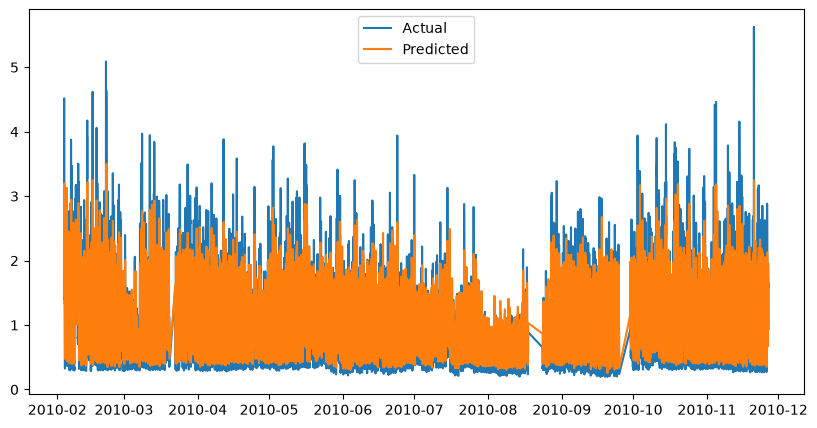

In [152]:
plt.figure(figsize=(10,5))
plt.plot(prediction_df.index,prediction_df['Actual'], label='Actual')
plt.plot(prediction_df.index, prediction_df['Predicted'], label='Predicted')
plt.legend()
plt.show()

In [153]:
# Uderstanding prediction errors
prediction_df['Error'] = prediction_df['Actual'] - prediction_df['Predicted']
prediction_df.head()

,Actual,Predicted,Error
Datetime,,,
2010-02-03 19:00:00,3.083167,1.460845,1.622322
2010-02-03 20:00:00,2.719600,2.614774,0.104826
2010-02-03 21:00:00,4.519200,2.159354,2.359846
2010-02-03 22:00:00,3.009900,3.199929,-0.190029
2010-02-03 23:00:00,1.860600,2.480251,-0.619651


#### Count underpredictions & Overpredictions

In [154]:
underprediction = (prediction_df['Error']>0).sum()
print("underprediction =",underprediction)

underprediction = 2432


In [155]:
overprediction = (prediction_df['Error']<0).sum()
print("overprediction =",overprediction)

overprediction = 4364


In [156]:
exact_prediction = (prediction_df['Error']==0).sum()
print("Exact prediction =",exact_prediction)

Exact prediction = 0


#### Mean of prediction errors

In [157]:
mean_error = prediction_df['Error'].mean()
print("Mean Prediction Error:",mean_error)

Mean Prediction Error: -0.04247992538642789


In [158]:
prediction_df['Absolute_Error'] = prediction_df['Error'].abs()
prediction_df.head()

,Actual,Predicted,Error,Absolute_Error
Datetime,,,,
2010-02-03 19:00:00,3.083167,1.460845,1.622322,1.622322
2010-02-03 20:00:00,2.719600,2.614774,0.104826,0.104826
2010-02-03 21:00:00,4.519200,2.159354,2.359846,2.359846
2010-02-03 22:00:00,3.009900,3.199929,-0.190029,0.190029
2010-02-03 23:00:00,1.860600,2.480251,-0.619651,0.619651


#### Largest Prediction error

In [159]:
prediction_df.sort_values(
    by = 'Absolute_Error',
    ascending=False).head()

,Actual,Predicted,Error,Absolute_Error
Datetime,,,,
2010-11-20 18:00:00,5.626833,1.580667,4.046167,4.046167
2010-02-21 11:00:00,5.090800,1.150263,3.940537,3.940537
2010-02-21 14:00:00,4.638200,1.785086,2.853114,2.853114
2010-06-23 21:00:00,3.941100,1.114747,2.826353,2.826353
2010-11-14 15:00:00,4.156567,1.443390,2.713177,2.713177


In [160]:
forecast_df.loc['2010-11-20 15:00:00':'2010-11-20 21:00:00']

,Global_active_power,lag 1,lag 2,lag 3,lag_24
Datetime,,,,,
2010-11-20 15:00:00,1.258167,1.051433,1.298000,1.130600,1.622867
2010-11-20 16:00:00,1.517033,1.258167,1.051433,1.298000,1.469700
2010-11-20 17:00:00,1.795300,1.517033,1.258167,1.051433,0.824267
2010-11-20 18:00:00,5.626833,1.795300,1.517033,1.258167,1.018467
2010-11-20 19:00:00,3.259700,5.626833,1.795300,1.517033,1.249767
2010-11-20 20:00:00,2.117133,3.259700,5.626833,1.795300,1.665267
2010-11-20 21:00:00,1.774100,2.117133,3.259700,5.626833,1.778367


<Axes: xlabel='Datetime'>

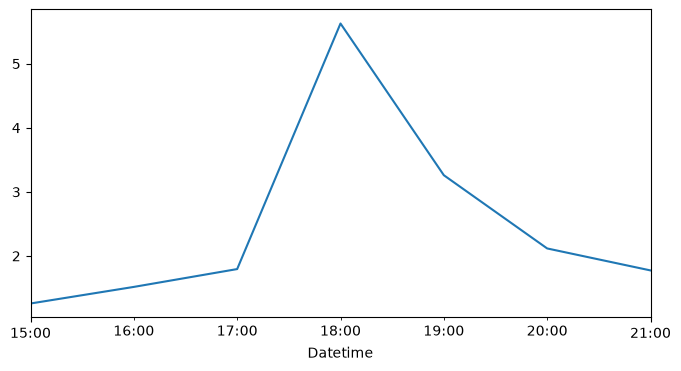

In [161]:
forecast_df.loc[
    '2010-11-20 15:00:00':'2010-11-20 21:00:00',
    'Global_active_power'
].plot(figsize=(8, 4))

<Axes: xlabel='Datetime'>

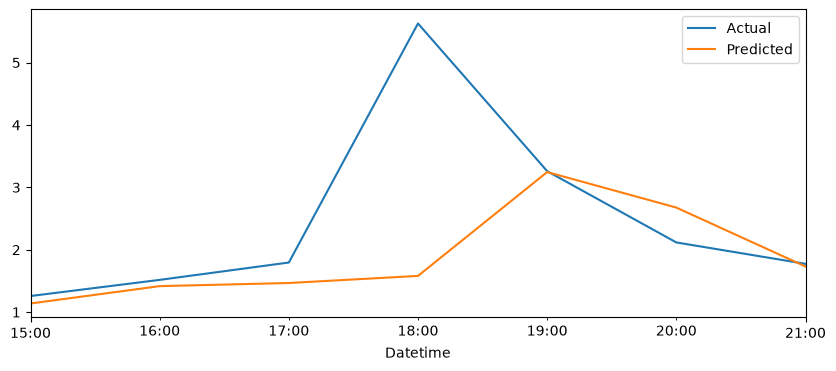

In [162]:
prediction_df.loc[
    '2010-11-20 15:00:00':'2010-11-20 21:00:00',
    ['Actual', 'Predicted']
].plot(figsize=(10, 4))

In [163]:
# sec. largest error
forecast_df.loc['2010-02-21 08:00:00':'2010-02-21 14:00:00']

,Global_active_power,lag 1,lag 2,lag 3,lag_24
Datetime,,,,,
2010-02-21 08:00:00,1.268333,0.401367,0.322733,0.311333,1.682933
2010-02-21 09:00:00,2.029133,1.268333,0.401367,0.322733,2.011467
2010-02-21 10:00:00,1.250367,2.029133,1.268333,0.401367,2.159600
2010-02-21 11:00:00,5.090800,1.250367,2.029133,1.268333,1.650433
2010-02-21 12:00:00,2.208200,5.090800,1.250367,2.029133,1.505233
2010-02-21 13:00:00,2.060600,2.208200,5.090800,1.250367,1.606067
2010-02-21 14:00:00,4.638200,2.060600,2.208200,5.090800,1.457967


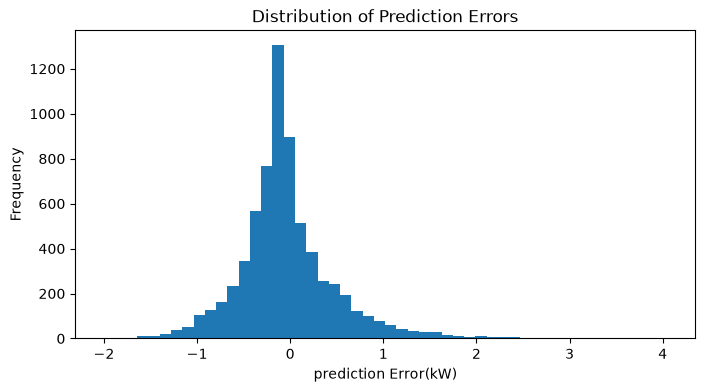

In [168]:
plt.figure(figsize=(8,4))
plt.hist(prediction_df['Error'],bins=50)
plt.xlabel('prediction Error(kW)')
plt.ylabel('Frequency')
plt.title("Distribution of Prediction Errors")
plt.show()

In [169]:
prediction_df[['Error','Absolute_Error']].describe()

,Error,Absolute_Error
count,6796.000000,6796.000000
mean,-0.042480,0.367567
std,0.516726,0.365630
min,-2.006040,0.000021
25%,-0.306941,0.113096
50%,-0.096166,0.252273
75%,0.160346,0.502588
max,4.046167,4.046167


##### Observation: Here the the average is (-ve) ,so we can see that model overpredicts,the model sometimes struggles to predict the unusual sudden changes